# Bab 5 – Model Linear dan Regularisasi

## Ringkasan Bab
Model linear cepat dilatih dan mudah ditafsirkan, sehingga sering dijadikan baseline. Bab ini mengulas **regresi linear**,
menjelaskan mengapa model ini bisa overfitting, lalu memperkenalkan **regularisasi**: **Ridge (L2)**, **Lasso (L1)**, dan
**Elastic Net (L1+L2)**. Dibahas pula teorinya, pengaruhnya terhadap koefisien, cara menyetel kekuatan penalti α,
dan tiga latihan praktik.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, make_regression, load_breast_cancer
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV,
                                  RidgeClassifier, LogisticRegression)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

## 1. Pengantar Model Linear
Regresi linear memprediksi ŷ = Xβ + b dengan meminimalkan **jumlah kuadrat residual** (OLS): min‖y − Xβ‖².
Asumsinya: hubungan linear, galat saling bebas, varians konstan, dan multikolinearitas rendah.
Masalahnya: bila fitur banyak atau saling berkorelasi, atau sampel sedikit, koefisien menjadi **besar dan tidak stabil**,
sehingga terjadi overfitting.

In [2]:
data = load_diabetes(as_frame=True); X, y = data.data, data.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
ols = LinearRegression().fit(Xtr, ytr)
print("OLS  R² train/test: %.3f / %.3f" % (ols.score(Xtr, ytr), ols.score(Xte, yte)))
print(pd.Series(ols.coef_, X.columns).round(1))

OLS  R² train/test: 0.519 / 0.485
age     47.7
sex   -242.0
bmi    532.0
bp     381.6
s1    -918.5
s2     508.3
s3     117.0
s4     269.5
s5     695.8
s6      26.3
dtype: float64


## 2. Teori dan Praktik Regularisasi
Regularisasi menambahkan **penalti terhadap besar koefisien** pada fungsi loss. Kita menerima sedikit bias demi varians yang lebih kecil:

* **Ridge (L2):** min ‖y − Xβ‖² + α‖β‖₂². Koefisien menyusut secara halus tetapi tidak pernah tepat nol, dan cocok untuk fitur yang saling berkorelasi.
* **Lasso (L1):** min (1/2n)‖y − Xβ‖² + α‖β‖₁. Koefisien bisa menjadi **tepat nol**, sehingga Lasso sekaligus memilih fitur.
* **Elastic Net:** gabungan keduanya dengan penalti α·ρ‖β‖₁ + α(1−ρ)/2 ‖β‖₂² (`l1_ratio` = ρ). Lebih stabil untuk fitur yang berkorelasi dalam kelompok.

Makin besar **α**, makin kuat regularisasinya. Fitur harus **distandarkan** sebelum diregularisasi.

## 3. Regresi Ridge dan Lasso

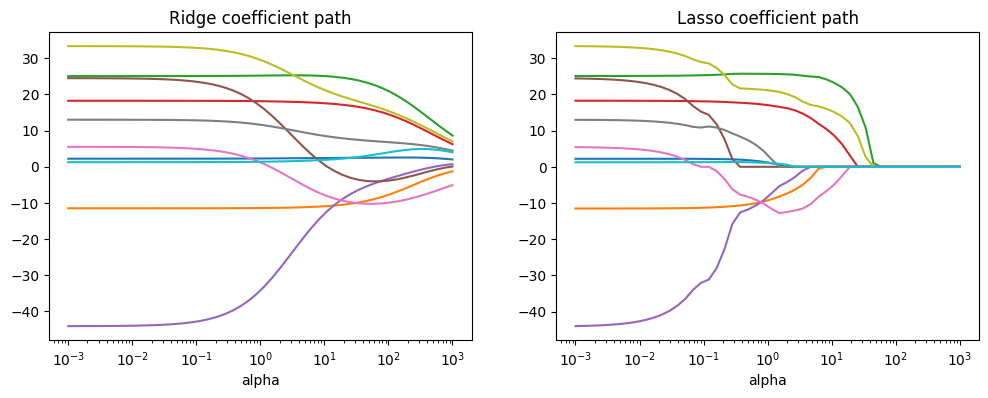

In [3]:
alphas = np.logspace(-3, 3, 50)
paths = {}
for name, M in [("Ridge", Ridge), ("Lasso", Lasso)]:
    paths[name] = np.array([make_pipeline(StandardScaler(), M(alpha=a, max_iter=50000)).fit(Xtr, ytr)[-1].coef_ for a in alphas])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, (name, c) in zip(ax, paths.items()):
    a_.plot(alphas, c); a_.set_xscale("log"); a_.set_title(f"{name} coefficient path"); a_.set_xlabel("alpha")
plt.show()

In [4]:
for name, M, a in [("OLS", LinearRegression, None), ("Ridge", Ridge, 10), ("Lasso", Lasso, 1.0)]:
    m = make_pipeline(StandardScaler(), M() if a is None else M(alpha=a)).fit(Xtr, ytr)
    nz = int(np.sum(m[-1].coef_ != 0))
    print(f"{name:6s} test R²={m.score(Xte, yte):.3f}  RMSE={mean_squared_error(yte, m.predict(Xte))**.5:.1f}  non-zero coefs={nz}")

OLS    test R²=0.485  RMSE=53.4  non-zero coefs=10
Ridge  test R²=0.488  RMSE=53.2  non-zero coefs=10
Lasso  test R²=0.496  RMSE=52.8  non-zero coefs=9


## 4. Elastic Net dan Regularisasi dalam Praktik
Gunakan estimator bawaan yang sudah menyertakan CV (`RidgeCV`, `LassoCV`, `ElasticNetCV`) agar nilai α dipilih secara efisien.

In [5]:
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))).fit(Xtr, ytr)
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0)).fit(Xtr, ytr)
enet  = make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.1, .5, .7, .9, .95], cv=5, random_state=0)).fit(Xtr, ytr)
print("Ridge alpha:", round(float(ridge[-1].alpha_), 3), "| R²:", round(ridge.score(Xte, yte), 3))
print("Lasso alpha:", round(float(lasso[-1].alpha_), 4), "| R²:", round(lasso.score(Xte, yte), 3))
print("ENet  alpha/l1_ratio:", round(float(enet[-1].alpha_), 4), enet[-1].l1_ratio_, "| R²:", round(enet.score(Xte, yte), 3))

Ridge alpha: 1.526 | R²: 0.486
Lasso alpha: 0.1062 | R²: 0.487
ENet  alpha/l1_ratio: 0.064 0.95 | R²: 0.487


## 5. Regularisasi pada Kasus Overfitting
Fitur polinomial berderajat tinggi mudah overfitting, dan regularisasi membantu memperbaikinya.

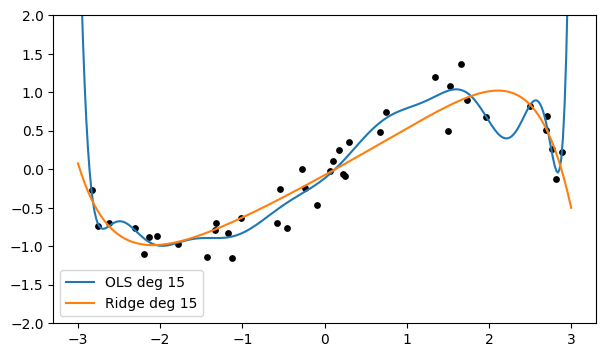

In [6]:
rng = np.random.default_rng(1)
xs = np.sort(rng.uniform(-3, 3, 40))[:, None]; ys = np.sin(xs).ravel() + rng.normal(0, .3, 40)
grid_x = np.linspace(-3, 3, 300)[:, None]
plt.figure(figsize=(7, 4)); plt.scatter(xs, ys, c="k", s=15)
for name, mdl in [("OLS deg 15", LinearRegression()), ("Ridge deg 15", Ridge(alpha=1.0))]:
    p = make_pipeline(PolynomialFeatures(15), StandardScaler(), mdl).fit(xs, ys)
    plt.plot(grid_x, p.predict(grid_x), label=name)
plt.ylim(-2, 2); plt.legend(); plt.show()

## 6. Latihan Praktik Model Regularisasi

### Latihan 1 – Klasifikasi dengan Ridge
`RidgeClassifier` mengubah label menjadi {−1, +1} lalu menjalankan regresi Ridge. Padanan probabilistiknya adalah
`LogisticRegression(penalty="l2", C=1/α)`.

In [7]:
Xb, yb = load_breast_cancer(return_X_y=True)
Xbt, Xbe, ybt, ybe = train_test_split(Xb, yb, test_size=.25, stratify=yb, random_state=42)
rc = make_pipeline(StandardScaler(), RidgeClassifier(alpha=1.0)).fit(Xbt, ybt)
print("RidgeClassifier accuracy:", round(rc.score(Xbe, ybe), 3))

RidgeClassifier accuracy: 0.958


### Latihan 2 – Menyetel Hyperparameter dengan Grid Search

In [8]:
gs = GridSearchCV(make_pipeline(StandardScaler(), RidgeClassifier()),
                  {"ridgeclassifier__alpha": np.logspace(-3, 3, 13)}, cv=5).fit(Xbt, ybt)
print("Best alpha:", gs.best_params_, "| CV:", round(gs.best_score_, 3), "| test:", round(gs.score(Xbe, ybe), 3))
l1 = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=0.1)).fit(Xbt, ybt)
print("L1 logistic non-zero coefs:", int((l1[-1].coef_ != 0).sum()), "of", Xb.shape[1], "| acc:", round(l1.score(Xbe, ybe), 3))

Best alpha: {'ridgeclassifier__alpha': np.float64(0.001)} | CV: 0.962 | test: 0.951
L1 logistic non-zero coefs: 7 of 30 | acc: 0.972


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


### Latihan 3 – Menerapkan Elastic Net
Pada data sintetis dengan banyak fitur yang tidak relevan, bandingkan OLS, Lasso, dan Elastic Net.

In [9]:
Xs, ys_, coef = make_regression(n_samples=120, n_features=60, n_informative=8, noise=15, coef=True, random_state=0)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys_, test_size=.3, random_state=0)
res = []
for name, m in [("OLS", LinearRegression()),
                ("Lasso", LassoCV(cv=5, random_state=0)),
                ("ElasticNet", ElasticNetCV(l1_ratio=[.2, .5, .8], cv=5, random_state=0))]:
    p = make_pipeline(StandardScaler(), m).fit(Xs_tr, ys_tr)
    res.append({"model": name, "test R²": round(p.score(Xs_te, ys_te), 3), "non-zero coefs": int((p[-1].coef_ != 0).sum())})
pd.DataFrame(res)

,model,test R²,non-zero coefs
0,OLS,0.976,60
1,Lasso,0.990,33
2,ElasticNet,0.959,58


**Kesimpulan:** pakai Ridge bila semua fitur berguna dan saling berkorelasi, Lasso bila ingin model yang jarang (seleksi fitur),
dan Elastic Net bila ingin keduanya. Selalu lakukan scaling dan setel α dengan cross-validation.